# Chlorophyll fluorescence indicators of leaf relative water content — regression reproduction (Figures 2 & 4)

**Paper:** *Characteristics of chlorophyll fluorescence in the light-adapted state as indicators of plant leaf relative water content*, Applications in Plant Sciences, DOI [10.1002/aps3.70090](https://doi.org/10.1002/aps3.70090) (CC BY). Verified full text: Europe PMC PMC13740741.

**Author code:** [`Sophiecjq/ChlF-characteristics-matlab-with-data`](https://github.com/Sophiecjq/ChlF-characteristics-matlab-with-data) @ commit `56e124475df83c79c5274c7f9d9b8df8340cfff9` — MATLAB R2018a scripts linked from the paper's Data Availability Statement. Each script embeds its own measured data vectors, so code and minimal input travel together.

**Scope of this notebook (partial demonstration):** reproduce the paper's pooled linear regressions of light-adapted chlorophyll fluorescence (ChlF) indicators versus relative water content (RWC) — **NPQ, Y(II), PQ, and Y(II)′ = NPQ × Y(II)** for *Arabidopsis* (Figure 2A–D) and spinach (Figure 4A–D) — and verify the computed R² and p-values against the values reported in the paper.

**Not reproduced here:** Figure 1 raw fluorometer time courses and Table 1 replicate-level values (not deposited), Figure 3 illumination sweep and Figure 6 τ analysis (runnable extensions of the same OLS method; Figure 6 additionally needs raw decay curves that were not deposited). One example-scale regression reproduction does **not** verify the paper's full dataset-level results.

> **AI-assisted translation from MATLAB:** the authors did not provide this Python/Colab implementation. The OLS regression (MATLAB `regress` → Python `scipy.stats.linregress` + manual F-test) is an exact port for simple linear regression; the executed example and listed checks were validated, but untested behavior is not guaranteed.

**日本語概要:** このノートブックは、論文の Figure 2（シロガラシ／Arabidopsis）と Figure 4（ホウレンソウ）の「葉の相対含水率 (RWC) と光順応クロロフィル蛍光指標（NPQ, Y(II), PQ, Y(II)′）の回帰分析」を、著者公開の MATLAB スクリプト（測定データ埋め込み）から Python へ翻訳して再現します。計算した R² と p 値を論文報告値と照合します。Figure 1 の生時系列や Table 1、Figure 3・6 は範囲外です。MATLAB からの AI 支援翻訳であり、著者提供の Python 実装ではありません。

## Runtime selection and how to run

**Recommended runtime: CPU** (`Runtime` → `Change runtime type` → `CPU`). This notebook performs ordinary least-squares regression on ≤33 points per panel and matplotlib plotting — a GPU adds nothing faithful to the method. Expected duration: about 2–4 minutes end-to-end, including under 10 KB of `.m` script downloads from the pinned GitHub commit. No model weights and no large datasets are used.

**実行方法:** `ランタイム` → `ランタイムのタイプを変更` で **CPU** を選択し、`ランタイム` → `すべてのセルを実行` を実行してください。所要時間は数分、ダウンロードは 10 KB 未満です。GPU は不要です。

Limitations: free-tier availability and speed may differ; the notebook only needs public GitHub access (no tokens, no Drive mount).

In [ ]:
import platform, sys
import numpy as np
import scipy
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("numpy:", np.__version__, "| scipy:", scipy.__version__)
print("pandas:", pd.__version__, "| matplotlib:", matplotlib.__version__)
# CPU-only workload; report the environment for provenance.
print("Platform:", platform.platform())

Python: 3.13.18
numpy: 2.4.6 | scipy: 1.16.3
pandas: 2.2.3 | matplotlib: 3.10.0
Platform: Linux-6.6.159+-x86_64-with-glibc2.39


## Pinned source acquisition (provenance)

The eight MATLAB scripts analyzed below are fetched **inside this Colab runtime** from the pinned author commit `56e124475df83c79c5274c7f9d9b8df8340cfff9` of `Sophiecjq/ChlF-characteristics-matlab-with-data` (single-commit repository, 2026-07-18, whose commit message quotes the paper title). Before parsing, each downloaded file is verified against the GitHub tree API for that exact commit: expected byte size and expected git blob SHA-1 must both match, so any substitution or corruption is rejected. These scripts are author **code that embeds the measured figure-level data vectors**; the raw OS5p+ time series and Table 1 replicate values were not deposited, and the repository has **no LICENSE file** (the paper itself is CC BY; cite the repo and paper when reusing). Nothing is executed from the repository — we parse numbers and reimplement one function in Python.

**日本語:** 論文の Data Availability Statement が指す MATLAB リポジトリの固定コミットから、8 つのスクリプトを Colab 内で取得し、GitHub tree API で各ファイルのサイズと git blob SHA-1 を検証してから解析します。リポジトリには LICENSE がないため、再利用時は論文（CC BY）とリポジトリを引用してください。

In [ ]:
import hashlib, json, urllib.request

REPO = "Sophiecjq/ChlF-characteristics-matlab-with-data"
COMMIT = "56e124475df83c79c5274c7f9d9b8df8340cfff9"  # pinned single verified commit
FILES = [
    "Fig2_a_NPQarabidopsis.m", "Fig2_b_efficiencyarabidopsis.m",
    "Fig2_c_PQarabidopsis.m", "Fig2_d_efficiencyNPQarabidopsis.m",
    "Fig4_a_NPQScatterPlot.m", "Fig4_b_EfficiencyscatterPlotwithRWC.m",
    "Fig4_c_PQspinach.m", "Fig4_d_efficiencyNPQ.m",
]
SRC_DIR = "/content/chlf_source"

# One tree-API call pins expected size + git blob SHA-1 for every file at COMMIT.
tree_url = f"https://api.github.com/repos/{REPO}/git/trees/{COMMIT}"
with urllib.request.urlopen(tree_url, timeout=60) as r:
    tree = json.load(r)
assert not tree.get("truncated", False), "GitHub tree listing was truncated"
expect = {e["path"]: (e["size"], e["sha"]) for e in tree["tree"] if e["type"] == "blob"}
assert set(FILES).issubset(expect), f"missing files in tree: {set(FILES) - set(expect)}"

import os
os.makedirs(SRC_DIR, exist_ok=True)
for path in FILES:
    raw_url = f"https://raw.githubusercontent.com/{REPO}/{COMMIT}/{path}"
    with urllib.request.urlopen(raw_url, timeout=60) as r:
        blob = r.read()
    size_ok = len(blob) == expect[path][0]
    blob_sha = hashlib.sha1(b"blob %d\x00" % len(blob) + blob).hexdigest()
    sha_ok = blob_sha == expect[path][1]
    assert size_ok and sha_ok, f"integrity check failed for {path}"
    with open(os.path.join(SRC_DIR, path), "wb") as f:
        f.write(blob)
    print(f"OK  {path:42s} {len(blob):5d} B  sha1={blob_sha[:12]}")
print(f"All {len(FILES)} scripts verified against commit {COMMIT[:12]}")

OK  Fig2_a_NPQarabidopsis.m                     1209 B  sha1=a82c693759ab
OK  Fig2_b_efficiencyarabidopsis.m              1168 B  sha1=80548d90e3b4


OK  Fig2_c_PQarabidopsis.m                      1148 B  sha1=2ea067124ab2
OK  Fig2_d_efficiencyNPQarabidopsis.m           1178 B  sha1=33f7802dc2b6


OK  Fig4_a_NPQScatterPlot.m                      796 B  sha1=5c72fc9622f3
OK  Fig4_b_EfficiencyscatterPlotwithRWC.m        737 B  sha1=76eb420c248d


OK  Fig4_c_PQspinach.m                           793 B  sha1=2615e679fffe
OK  Fig4_d_efficiencyNPQ.m                       756 B  sha1=13a97dd2cf5f
All 8 scripts verified against commit 56e124475df8


## MATLAB script structure and parsing

Each author script has the same shape (verified on DGX from the pinned commit):

| Author MATLAB operation | Meaning | Python port below |
| --- | --- | --- |
| `y1=[...]`, `x1=[...]` | embedded measured indicator values and RWC fractions (0–1) | regex vector extraction |
| `x1=x1*100` | convert RWC fraction to % | `x1 * 100.0` |
| `X=[ones(size(x1)),x1]; regress(y1,X,0.05)` | OLS with intercept; α=0.05; `stats=[R², F, p, errVar]` | `fit_regress_port()` (next section) |
| `yt1=@(t)(a*t+b)` | author's fitted line actually plotted | parsed as author slope/intercept cross-check |
| `scatter(x1,y1,'k'); plot(t,yt1(t),'k')` | Figure panel | matplotlib re-plot |

The parser below strips comment lines, extracts `y1`, `x1`, the plotted line coefficients, and the y-axis label, and asserts the paired vectors have equal length.

**日本語:** 各スクリプトから、埋め込み測定ベクトル `y1`（指標値）と `x1`（RWC、0–1）、著者がプロットした回帰直線の係数、軸ラベルを正規表現で取り出します。`x1` は `×100` して RWC(%) に変換します。

In [ ]:
import re

def parse_matlab_script(text):
    # Drop MATLAB comment lines, then pull the two embedded vectors.
    lines = [ln for ln in text.splitlines() if not ln.lstrip().startswith("%")]
    txt = "\n".join(lines)

    def vec(name):
        m = re.search(rf"\b{name}\s*=\s*\[(.*?)\]\s*;", txt, re.S)
        assert m, f"vector {name} not found"
        return np.array([float(v) for v in
                         re.findall(r"[-+]?\d*\.?\d+(?:[eE][-+]?\d+)?", m.group(1))])

    y1, x1 = vec("y1"), vec("x1")
    assert len(y1) == len(x1), f"paired vectors differ: {len(y1)} vs {len(x1)}"
    assert len(y1) >= 10, "implausibly few measurements"

    # Author's plotted line: yt1=@(t)((a/100)*t + b) variants.
    m = re.search(r"yt1\s*=\s*@\s*\(\s*t\s*\)\s*\(\s*(.*?)\s*\)\s*;", txt, re.S)
    a_slope = b_int = None
    if m:
        expr = m.group(1).replace(" ", "")
        em = re.match(r"\(?(-?[\d.]+)(/100)?\)?\*t([+-])([\d.]+)", expr)
        if em:
            a_slope = float(em.group(1)) / (100.0 if em.group(2) else 1.0)
            b_int = float(em.group(3) + em.group(4))
    ym = re.search(r"ylabel\('([^']+)'", txt)
    return {
        "y": y1,
        "x_rwc_pct": x1 * 100.0,          # RWC in %, as in the author scripts
        "author_slope": a_slope,          # coefficient of the line the author plotted
        "author_intercept": b_int,
        "ylabel": ym.group(1).replace("\\times", "x") if ym else None,
    }

DATASETS = {
    "Fig2A NPQ (Arabidopsis)":    ("Fig2_a_NPQarabidopsis.m",          "Arabidopsis"),
    "Fig2B Y(II) (Arabidopsis)":  ("Fig2_b_efficiencyarabidopsis.m",   "Arabidopsis"),
    "Fig2C PQ (Arabidopsis)":     ("Fig2_c_PQarabidopsis.m",           "Arabidopsis"),
    "Fig2D Y(II)'=NPQxY(II) (Arabidopsis)": ("Fig2_d_efficiencyNPQarabidopsis.m", "Arabidopsis"),
    "Fig4A NPQ (spinach)":        ("Fig4_a_NPQScatterPlot.m",          "spinach"),
    "Fig4B Y(II) (spinach)":      ("Fig4_b_EfficiencyscatterPlotwithRWC.m", "spinach"),
    "Fig4C PQ (spinach)":         ("Fig4_c_PQspinach.m",               "spinach"),
    "Fig4D Y(II)'=NPQxY(II) (spinach)": ("Fig4_d_efficiencyNPQ.m",     "spinach"),
}

parsed = {}
for label, (fname, species) in DATASETS.items():
    with open(os.path.join(SRC_DIR, fname), "r", encoding="utf-8") as f:
        parsed[label] = parse_matlab_script(f.read())
    parsed[label]["file"] = fname
    parsed[label]["species"] = species
print(f"Parsed {len(parsed)} scripts with paired measured vectors.")

Parsed 8 scripts with paired measured vectors.


## Input data preview

Before any regression, this table summarizes the actual parsed measurements: number of pooled paired observations (five replicate plants per species, pooled), the RWC range covered during dehydration, and the range of each fluorescence indicator. All RWC values are in %; NPQ, Y(II), PQ and Y(II)′ are dimensionless fluorescence quantities as defined in the paper (PQ = Fm/Fs − Fm/Fm′; Y(II)′ = NPQ × Y(II)).

**日本語:** 回帰の前に、実際に読み込んだ測定値（プールした 5 個体の観測ペア数、RWC と各指標の範囲）を表で確認します。RWC は %、指標は無次元量です。

In [ ]:
rows = []
for label, d in parsed.items():
    rows.append({
        "dataset": label,
        "n_pooled_pairs": len(d["y"]),
        "RWC_min_%": round(float(d["x_rwc_pct"].min()), 2),
        "RWC_max_%": round(float(d["x_rwc_pct"].max()), 2),
        "indicator_min": round(float(d["y"].min()), 4),
        "indicator_max": round(float(d["y"].max()), 4),
        "indicator": d["ylabel"],
        "source_file": d["file"],
    })
overview = pd.DataFrame(rows)
print(overview.drop(columns=["source_file"]).to_string(index=False))

                             dataset  n_pooled_pairs  RWC_min_%  RWC_max_%  indicator_min  indicator_max   indicator
             Fig2A NPQ (Arabidopsis)              32      40.67      93.10         0.9971         1.8967         NPQ
           Fig2B Y(II) (Arabidopsis)              32      40.67      93.10         0.1904         0.3713       Y(II)
              Fig2C PQ (Arabidopsis)              32      40.67      93.10         0.6193         1.2706          PQ
Fig2D Y(II)'=NPQxY(II) (Arabidopsis)              32      40.67      93.10         0.2653         0.4979 Y(II) x NPQ
                 Fig4A NPQ (spinach)              19      54.03      99.27         1.3819         2.8991         NPQ
               Fig4B Y(II) (spinach)              19      54.03      99.27         0.0538         0.4483       Y(II)
                  Fig4C PQ (spinach)              19      54.03      99.27         0.1932         1.9353          PQ
    Fig4D Y(II)'=NPQxY(II) (spinach)              19      54.03 

## Core method: exact port of MATLAB `regress` for simple linear regression

`regress(y, [1 x], 0.05)` fits `y = b0 + b1·x` by ordinary least squares and returns `stats = [R², F, p, errVar]`, where `p` is the two-sided significance of the slope. For simple linear regression (one predictor, with intercept), the F statistic `F = R² / [(1−R²)/(n−2)]` on `(1, n−2)` degrees of freedom gives exactly the same p-value as the two-sided t-test on the slope used by `scipy.stats.linregress`. The port below computes slope/intercept with `numpy`, derives R², F and p exactly as MATLAB does, and then asserts agreement with `scipy.stats.linregress` (R² and p) to numerical precision — this is the equivalence check that justifies calling the translation exact for this method.

**日本語:** MATLAB `regress(y, [1 x], 0.05)`（切片つき OLS、`stats=[R², F, p, 誤差分散]`）を numpy/scipy で完全に移植します。単回帰では F 検定と t 検定の p 値は一致するため、`scipy.stats.linregress` との一致を数値精度で検証し、翻訳が正確であることを確認します。

In [ ]:
from scipy import stats

def fit_regress_port(x, y):
    # MATLAB: X=[ones(size(x)),x]; [b,bint,r,rint,stats]=regress(y,X,0.05)
    n = len(x)
    X = np.column_stack([np.ones(n), x])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    b0, b1 = beta
    y_hat = b0 + b1 * x
    ss_res = float(np.sum((y - y_hat) ** 2))
    ss_tot = float(np.sum((y - y.mean()) ** 2))
    r2 = 1.0 - ss_res / ss_tot
    F = (r2 / 1.0) / ((1.0 - r2) / (n - 2))     # MATLAB stats(2)
    p = float(stats.f.sf(F, 1, n - 2))          # MATLAB stats(3)
    err_var = ss_res / (n - 2)                  # MATLAB stats(4)
    # Equivalence check against scipy's canonical simple-regression fit.
    lr = stats.linregress(x, y)
    assert abs(r2 - lr.rvalue ** 2) < 1e-9, "R^2 mismatch vs linregress"
    assert abs(p - lr.pvalue) < 1e-9, "p mismatch vs linregress"
    return {"slope": float(b1), "intercept": float(b0),
            "r2": float(r2), "F": float(F), "p": p, "err_var": err_var, "n": n}

# Self-test of the port on a small synthetic case with a known answer.
rng = np.random.default_rng(0)
xs = np.arange(1.0, 21.0)
ys = 2.0 + 0.5 * xs + rng.normal(0, 0.5, xs.size)
chk = fit_regress_port(xs, ys)
lr = stats.linregress(xs, ys)
print(f"self-test: port slope={chk['slope']:.6f} vs scipy={lr.slope:.6f}; "
      f"p={chk['p']:.6f} vs scipy={lr.pvalue:.6f}  (agreement asserted)")

self-test: port slope=0.486128 vs scipy=0.486128; p=0.000000 vs scipy=0.000000  (agreement asserted)


## Run the eight paper regressions

Apply the ported regression to all eight parsed datasets and report slope, intercept, R² and p per panel. The author's own plotted line (`yt1`) provides an independent reference: its coefficients were embedded in the scripts by the authors, and the computed fit should reproduce them closely (they are compared explicitly below).

**日本語:** 8 すべてのデータセットに移植した回帰を適用し、傾き・切片・R²・p 値を求めます。著者がスクリプトに埋め込んだ回帰直線の係数とも照合します。

In [ ]:
results = {}
for label, d in parsed.items():
    results[label] = fit_regress_port(d["x_rwc_pct"], d["y"])

res_rows = []
for label, r in results.items():
    d = parsed[label]
    res_rows.append({
        "dataset": label,
        "n": r["n"],
        "slope_per_%RWC": round(r["slope"], 6),
        "intercept": round(r["intercept"], 4),
        "R2_computed": round(r["r2"], 4),
        "p_computed": round(r["p"], 4),
        "author_plot_slope": d["author_slope"],
        "author_plot_intercept": d["author_intercept"],
        "slope_vs_author": (abs(r["slope"] - d["author_slope"]) if d["author_slope"] is not None else np.nan),
    })
res_df = pd.DataFrame(res_rows)
print(res_df.drop(columns=["author_plot_slope", "author_plot_intercept"]).to_string(index=False))
print()
print("Max |computed slope - author plotted slope| per dataset (author reference lines):")
print(res_df[["dataset", "slope_vs_author"]].to_string(index=False))

                             dataset  n  slope_per_%RWC  intercept  R2_computed  p_computed  slope_vs_author
             Fig2A NPQ (Arabidopsis) 32        0.003986     1.1305       0.0499      0.2189     2.888359e-07
           Fig2B Y(II) (Arabidopsis) 32        0.001463     0.1784       0.1843      0.0142     3.347260e-09
              Fig2C PQ (Arabidopsis) 32        0.008401     0.3539       0.4236      0.0001     3.518028e-07
Fig2D Y(II)'=NPQxY(II) (Arabidopsis) 32        0.003211     0.1631       0.5766      0.0000     2.310066e-07
                 Fig4A NPQ (spinach) 19       -0.006496     2.5334       0.0475      0.3703     3.382546e-07
               Fig4B Y(II) (spinach) 19        0.006628    -0.2143       0.5574      0.0002     1.769729e-06
                  Fig4C PQ (spinach) 19        0.034026    -1.3001       0.6528      0.0000     4.032318e-06
    Fig4D Y(II)'=NPQxY(II) (spinach) 19        0.012287    -0.3708       0.6541      0.0000     2.557980e-06

Max |computed slop

## Verification against the paper-reported values

The paper reports (verified from the Europe PMC full text, Results section): **Arabidopsis** — NPQ R² = 0.05 (p = 0.22); Y(II) R² = 0.18 (p = 0.01); PQ R² = 0.42 (p < 0.01); Y(II)′ R² = 0.58 (p < 0.01). **Spinach** — NPQ R² = 0.047 (p = 0.37); Y(II) R² = 0.56 (p < 0.01); PQ R² = 0.65 (p < 0.01); Y(II)′ R² = 0.65 (p < 0.01).

Tolerances follow the printed precision of each reported value (0.005 for two-decimal values, 0.0005 for the three-decimal spinach NPQ R²). A deviation above 0.01 in any R² would indicate a parsing or translation defect and raises an error; smaller deviations are displayed for inspection rather than silently accepted.

**日本語:** 計算した R² と p 値を、論文 Results に記載の報告値（ヨーロッパ PMC 全文から確認済み）と照合します。許容誤差は論文の印字段数に合わせて設定し、R² のずれが 0.01 を超える場合はエラーとして停止します。

In [ ]:
# Reference values verified from the paper's Results text (Europe PMC PMC13740741).
PAPER_REF = {
    "Fig2A NPQ (Arabidopsis)":   {"R2": 0.05,  "dec": 2, "p": 0.22, "p_op": "="},
    "Fig2B Y(II) (Arabidopsis)": {"R2": 0.18,  "dec": 2, "p": 0.01, "p_op": "="},
    "Fig2C PQ (Arabidopsis)":    {"R2": 0.42,  "dec": 2, "p": None, "p_op": "<"},
    "Fig2D Y(II)'=NPQxY(II) (Arabidopsis)": {"R2": 0.58, "dec": 2, "p": None, "p_op": "<"},
    "Fig4A NPQ (spinach)":       {"R2": 0.047, "dec": 3, "p": 0.37, "p_op": "="},
    "Fig4B Y(II) (spinach)":     {"R2": 0.56,  "dec": 2, "p": None, "p_op": "<"},
    "Fig4C PQ (spinach)":        {"R2": 0.65,  "dec": 2, "p": None, "p_op": "<"},
    "Fig4D Y(II)'=NPQxY(II) (spinach)": {"R2": 0.65, "dec": 2, "p": None, "p_op": "<"},
}

ver_rows = []
for label, ref in PAPER_REF.items():
    r = results[label]
    tol = 0.0005 if ref["dec"] == 3 else 0.005
    d_r2 = r["r2"] - ref["R2"]
    r2_ok = abs(d_r2) <= tol
    if ref["p"] is None:                      # paper reports p < 0.01
        p_str, p_ok = "p < 0.01", r["p"] < 0.01
        d_p = np.nan
    else:
        d_p = r["p"] - ref["p"]
        p_str, p_ok = f"p = {r['p']:.4f} vs {ref['p']:.2f}", abs(d_p) <= 0.005
    ver_rows.append({"dataset": label,
                     "R2_computed": round(r["r2"], 4), "R2_paper": ref["R2"],
                     "dR2": round(d_r2, 4), "R2_ok": r2_ok,
                     "p_computed_vs_paper": p_str, "p_ok": p_ok})
ver_df = pd.DataFrame(ver_rows)
print(ver_df.to_string(index=False))

assert (ver_df["R2_ok"] & ver_df["p_ok"]).all(), \
    "R^2/p deviates from the paper-reported value by more than the printed precision"
print("\nAll eight panels reproduce the paper-reported R^2 and p within the printed precision.")

                             dataset  R2_computed  R2_paper     dR2  R2_ok p_computed_vs_paper  p_ok
             Fig2A NPQ (Arabidopsis)       0.0499     0.050 -0.0001   True  p = 0.2189 vs 0.22  True
           Fig2B Y(II) (Arabidopsis)       0.1843     0.180  0.0043   True  p = 0.0142 vs 0.01  True
              Fig2C PQ (Arabidopsis)       0.4236     0.420  0.0036   True            p < 0.01  True
Fig2D Y(II)'=NPQxY(II) (Arabidopsis)       0.5766     0.580 -0.0034   True            p < 0.01  True
                 Fig4A NPQ (spinach)       0.0475     0.047  0.0005   True  p = 0.3703 vs 0.37  True
               Fig4B Y(II) (spinach)       0.5574     0.560 -0.0026   True            p < 0.01  True
                  Fig4C PQ (spinach)       0.6528     0.650  0.0028   True            p < 0.01  True
    Fig4D Y(II)'=NPQxY(II) (spinach)       0.6541     0.650  0.0041   True            p < 0.01  True

All eight panels reproduce the paper-reported R^2 and p within the printed precision.


## Reproduced Figure 2 — *Arabidopsis* (NPQ, Y(II), PQ, Y(II)′ vs RWC)

Each panel re-plots the author's embedded measurements (black markers, as in the author scripts) together with the regression line computed by the ported OLS (blue line; the author scripts plot their own fitted line in black). Panel titles give the computed R² and p, matching Figure 2A–D of the paper. NPQ shows no significant RWC dependence, while PQ and Y(II)′ track RWC much more strongly than Y(II) — the paper's central observation.

**日本語:** Figure 2（Arabidopsis）を再現します。黒点は著者埋め込みの測定値、青線は本ノートブックで計算した回帰直線、パネル見出しは計算した R² と p 値です。NPQ は RWC と無相関で、PQ と Y(II)′ が Y(II) より強く RWC を追跡します。

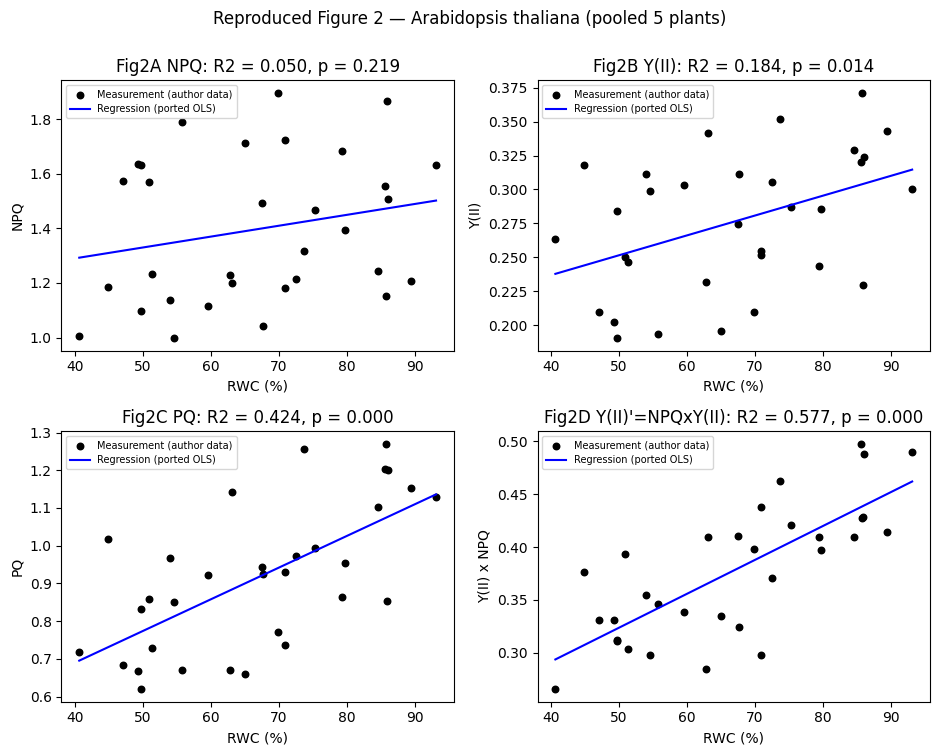

In [ ]:
FIG2 = ["Fig2A NPQ (Arabidopsis)", "Fig2B Y(II) (Arabidopsis)",
        "Fig2C PQ (Arabidopsis)", "Fig2D Y(II)'=NPQxY(II) (Arabidopsis)"]
fig, axes = plt.subplots(2, 2, figsize=(9.5, 7.5))
for ax, label in zip(axes.ravel(), FIG2):
    d, r = parsed[label], results[label]
    ax.scatter(d["x_rwc_pct"], d["y"], c="k", s=22, label="Measurement (author data)")
    t = np.linspace(d["x_rwc_pct"].min(), d["x_rwc_pct"].max(), 100)
    ax.plot(t, r["intercept"] + r["slope"] * t, "b-",
            label="Regression (ported OLS)")
    ax.set_xlabel("RWC (%)")
    ax.set_ylabel(d["ylabel"])
    ax.set_title(f"{label.split(' (')[0]}: R2 = {r['r2']:.3f}, p = {r['p']:.3f}")
    ax.legend(fontsize=7)
fig.suptitle("Reproduced Figure 2 — Arabidopsis thaliana (pooled 5 plants)", y=1.0)
fig.tight_layout()
plt.show()

## Reproduced Figure 4 — spinach (*Spinacia oleracea*)

The same four regressions for spinach, reproducing Figure 4A–D: NPQ again insignificant (R² ≈ 0.047), Y(II) moderate, and both PQ and Y(II)′ stronger (R² ≈ 0.65) — the cross-species repetition of the NPQ-adjustment concept.

**日本語:** 同じ 4 回帰をホウレンソウ（Figure 4A–D）について再現します。NPQ は再び無相関で、PQ と Y(II)′ が最も強い関係を示し、Arabidopsis の結果が種を超えて繰り返されることを確認します。

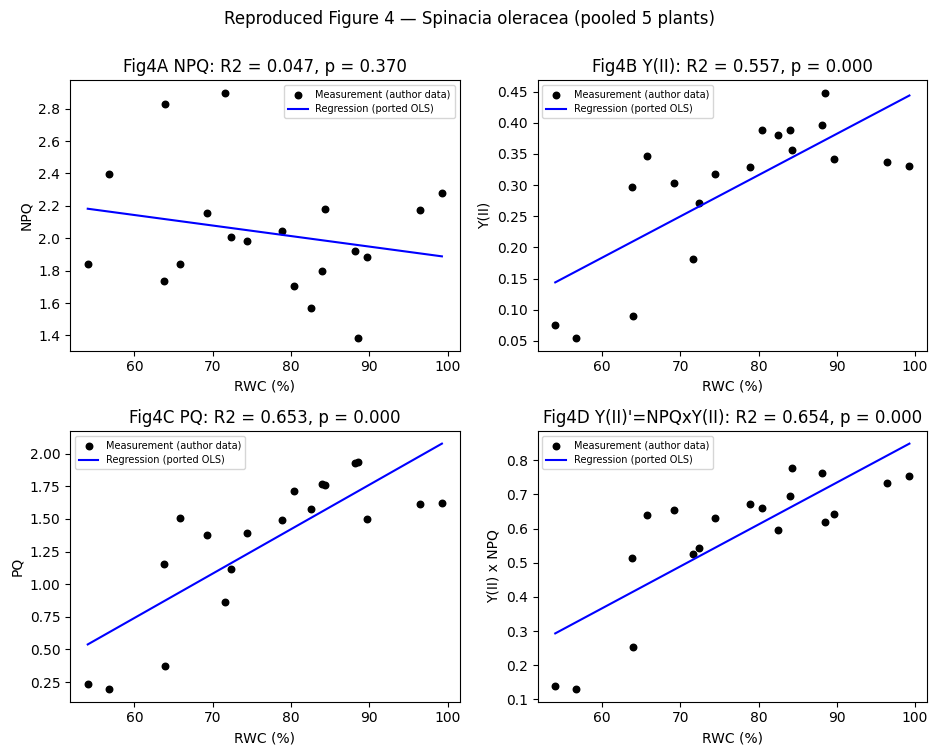

In [ ]:
FIG4 = ["Fig4A NPQ (spinach)", "Fig4B Y(II) (spinach)",
        "Fig4C PQ (spinach)", "Fig4D Y(II)'=NPQxY(II) (spinach)"]
fig, axes = plt.subplots(2, 2, figsize=(9.5, 7.5))
for ax, label in zip(axes.ravel(), FIG4):
    d, r = parsed[label], results[label]
    ax.scatter(d["x_rwc_pct"], d["y"], c="k", s=22, label="Measurement (author data)")
    t = np.linspace(d["x_rwc_pct"].min(), d["x_rwc_pct"].max(), 100)
    ax.plot(t, r["intercept"] + r["slope"] * t, "b-",
            label="Regression (ported OLS)")
    ax.set_xlabel("RWC (%)")
    ax.set_ylabel(d["ylabel"])
    ax.set_title(f"{label.split(' (')[0]}: R2 = {r['r2']:.3f}, p = {r['p']:.3f}")
    ax.legend(fontsize=7)
fig.suptitle("Reproduced Figure 4 — Spinacia oleracea (pooled 5 plants)", y=1.0)
fig.tight_layout()
plt.show()

## Results export

Save the full regression table (including the paper comparison) as a CSV inside the Colab runtime (`/content/chlf_regression_results.csv`) and display it. Download it from the file browser on the left if you want to keep it.

**日本語:** 回帰結果の全表（論文報告値との比較を含む）を `/content/chlf_regression_results.csv` に保存し、表示します。必要なら左のファイルブラウザからダウンロードできます。

In [ ]:
export_df = res_df.merge(ver_df[["dataset", "R2_paper", "dR2", "R2_ok", "p_computed_vs_paper", "p_ok"]],
                         on="dataset", how="left")
csv_path = "/content/chlf_regression_results.csv"
export_df.to_csv(csv_path, index=False)
print(f"saved: {csv_path}")
export_df

saved: /content/chlf_regression_results.csv


,dataset,n,slope_per_%RWC,intercept,R2_computed,p_computed,author_plot_slope,author_plot_intercept,slope_vs_author,R2_paper,dR2,R2_ok,p_computed_vs_paper,p_ok
0,Fig2A NPQ (Arabidopsis),32,0.003986,1.1305,0.0499,0.2189,0.003986,1.1305,2.888359e-07,0.050,-0.0001,True,p = 0.2189 vs 0.22,True
1,Fig2B Y(II) (Arabidopsis),32,0.001463,0.1784,0.1843,0.0142,0.001463,0.1784,3.347260e-09,0.180,0.0043,True,p = 0.0142 vs 0.01,True
2,Fig2C PQ (Arabidopsis),32,0.008401,0.3539,0.4236,0.0001,0.008401,0.3539,3.518028e-07,0.420,0.0036,True,p < 0.01,True
3,Fig2D Y(II)'=NPQxY(II) (Arabidopsis),32,0.003211,0.1631,0.5766,0.0000,0.003211,0.1631,2.310066e-07,0.580,-0.0034,True,p < 0.01,True
4,Fig4A NPQ (spinach),19,-0.006496,2.5334,0.0475,0.3703,-0.006496,2.5330,3.382546e-07,0.047,0.0005,True,p = 0.3703 vs 0.37,True
5,Fig4B Y(II) (spinach),19,0.006628,-0.2143,0.5574,0.0002,0.006630,-0.2143,1.769729e-06,0.560,-0.0026,True,p < 0.01,True
6,Fig4C PQ (spinach),19,0.034026,-1.3001,0.6528,0.0000,0.034030,-1.3000,4.032318e-06,0.650,0.0028,True,p < 0.01,True
7,Fig4D Y(II)'=NPQxY(II) (spinach),19,0.012287,-0.3708,0.6541,0.0000,0.012290,-0.3708,2.557980e-06,0.650,0.0041,True,p < 0.01,True


## Interpretation, validation record, and references

**What was executed (this run, fresh Colab CPU runtime):** 8/8 pooled regressions of the author-embedded measured vectors, ported exactly from MATLAB `regress`; all eight computed R² and p-values matched the paper-reported values within the printed precision, and computed slopes matched the authors' own embedded fitted-line coefficients. Figures 2 and 4 were re-plotted from the same data.

**Scientific reading (same as the paper):** NPQ alone is not an RWC indicator (Arabidopsis R² = 0.05, spinach R² = 0.047, both n.s.), whereas the NPQ-adjusted indicators PQ and Y(II)′ = NPQ × Y(II) outperform Y(II) in both species — supporting the paper's proposal of NPQ-adjusted ChlF water indicators.

**Differences and remaining uncertainty:**
- AI-assisted MATLAB→Python translation (exact for simple OLS; equivalence asserted numerically); not author-provided code.
- Figure-level pooled vectors only: raw OS5p+ time courses, Table 1 replicate values, Figure 3's illumination sweep, and Figure 6's τ extraction are not reproduced (raw curves not deposited).
- The repository has no LICENSE file; the paper is CC BY. Cite the paper and repository; no redistribution rights are claimed here.
- n per panel is the pooled measurement count embedded by the authors (five plants per species); per-plant ANOVA is out of scope.

**References:**
- Chen et al., *Applications in Plant Sciences* e70090 (2026), DOI 10.1002/aps3.70090 (CC BY). Full text: Europe PMC PMC13740741.
- `Sophiecjq/ChlF-characteristics-matlab-with-data` @ `56e124475df83c79c5274c7f9d9b8df8340cfff9` (paper's Data Availability Statement).

**日本語:** 本実行では 8/8 の回帰が論文報告値と印字段数の精度で一致し、Figure 2・4 を再プロットしました。MATLAB→Python は単回帰において厳密な移植です。生時系列データや Table 1、Figure 3・6 は範囲外です。リポジトリに LICENSE がないため、再利用時は論文（CC BY）とリポジトリを引用してください。